
## Configs

In [ ]:
from argparse import Namespace
import torch
import torch.nn as nn
import torch.optim as optim

from engine.seed import set_global_seed
from data_provider.data_factory import data_factory
from models.transformer import TransformerModel
from engine.trainer import Trainer
from utils.exp_utils import build_run_paths_from_configs


In [ ]:
# 1. CENTRAL CONFIGURATION (Transformer VARIATE)
configs = Namespace(
    # -- Experiment --
    model_name="transformer",
    token_style="variate",   # time | variate
    seed=42,
    verbose=True,

    # -- Data --
    data_name="ECL",   # ETTh1
    window=96,
    horizon=96,
    stride=1,
    batch_size=32,
    ratios=(0.7, 0.15, 0.15),

    # -- Model common --
    channels=321,   # 7
    d_model=512,
    num_layers=3,
    dropout=0.1,

    # -- Transformer specific --
    nhead=8,
    dim_feedforward=512,       # if None = 4*d_model 
    activation="gelu",           # gelu | relu
    norm_first=False, 
    layer_norm_eps=1e-5,
    batch_first=True,

    # -- Time-token extras (Ignored if variate) --
    pooling="attention",          # "last" | "attention"
    temperature=1.0,              # only used if pooling="attention"
    pos_emb="learnable",          # "sin" | "learnable"

    # -- Optimization --
    lr=1e-4,
    weight_decay=1e-5,
    scheduler_factor=0.5,
    scheduler_patience=3,
    min_lr=1e-7,
    early_stop_patience=10,
    num_epochs=30,

    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    
)

## Load DataModule

In [3]:
set_global_seed(seed=configs.seed, verbose=False, deterministic=True)


dm = data_factory(
    data_name=configs.data_name,
    window=configs.window,
    horizon=configs.horizon,
    stride=configs.stride,
    batch_size=configs.batch_size,
    ratios=configs.ratios,
    verbose=False,
)

train_loader, val_loader, test_loader = dm.setup(
    seed=configs.seed,
    verbose=True,
)


--- 📊 DataModule: ECL ---
Window: 96 | Horizon: 96 | Stride: 1
Batch Size: 32 | Ratios: (0.7, 0.15, 0.15)
🧩 Created raw splits:
   Train: X=(18412, 321), y=(18412, 321)
   Val:   X=(3946, 321), y=(3946, 321)
   Test:  X=(3946, 321), y=(3946, 321)
🔁 Created windowed data: X_seq (18221, 96, 321), y_seq (18221, 96, 321)
🔁 Created windowed data: X_seq (3755, 96, 321), y_seq (3755, 96, 321)
🔁 Created windowed data: X_seq (3755, 96, 321), y_seq (3755, 96, 321)
📦 Train batch → X: torch.Size([32, 96, 321]), Y: torch.Size([32, 96, 321])


## Load model

In [5]:
set_global_seed(seed=configs.seed, verbose=False, deterministic=True)
# print(f"Using device: {configs.device}")
model = TransformerModel(configs=configs, verbose=True).to(configs.device)



--- 🤖 Model: TransformerModel Ready ---
Family: transformer | Token Style: variate
Common: channels=321 | d_model=512 | layers=3 | dropout=0.1
Transformer: nhead=8 | d_ff=512 | act=gelu | norm_first=False
Params: 4,832,864 | Size: 18.44 MB



### optimizer, loss fn. and scheduler

In [6]:
set_global_seed(seed=configs.seed, verbose=False, deterministic=True)

optimizer = optim.AdamW(
    params=model.parameters(),
    lr=configs.lr,
    weight_decay=configs.weight_decay,
)

criterion = nn.MSELoss()

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer=optimizer,
    mode="min",
    factor=configs.scheduler_factor,
    patience=configs.scheduler_patience,
    min_lr=configs.min_lr,
)

## Training

In [7]:
paths = build_run_paths_from_configs(
    configs=configs,
    seed=configs.seed,
    root_dir="runs",
    verbose=True,  
)

save_run_dir = paths["run_root"]
save_artifacts_dir = paths["train_dir"]
save_test_dir = paths["test_dir"]



[exp_utils] Run directories created:
  run_root : runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-27_22-39
  train_dir: runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-27_22-39/train
  test_dir : runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-27_22-39/test



In [11]:
set_global_seed(seed=configs.seed, verbose=False, deterministic=True)

trainer = Trainer(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    device=configs.device,
    patience=5,
    save_artifacts_dir=save_artifacts_dir,   # None
    save_run_dir=save_run_dir,         # None
    run_config=configs,
    verbose=True,
)

history = trainer.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=20,
    trial=None,
    save_all=True,
    verbose=True,
)

🧾 Run summary saved to runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-27_22-39/run_summary.json
Starting training... Checkpoints: runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-27_22-39/train
Epoch 00 | Tr_MSE: 0.2507 | Val_MSE: 0.1779
Epoch 01 | Tr_MSE: 0.1960 | Val_MSE: 0.1618
Epoch 02 | Tr_MSE: 0.1825 | Val_MSE: 0.1555
Epoch 03 | Tr_MSE: 0.1744 | Val_MSE: 0.1532
Epoch 04 | Tr_MSE: 0.1686 | Val_MSE: 0.1498
Epoch 05 | Tr_MSE: 0.1639 | Val_MSE: 0.1451
Epoch 06 | Tr_MSE: 0.1601 | Val_MSE: 0.1436
Epoch 07 | Tr_MSE: 0.1570 | Val_MSE: 0.1419
Epoch 08 | Tr_MSE: 0.1540 | Val_MSE: 0.1402
Epoch 09 | Tr_MSE: 0.1515 | Val_MSE: 0.1381
Epoch 10 | Tr_MSE: 0.1494 | Val_MSE: 0.1405
Epoch 11 | Tr_MSE: 0.1471 | Val_MSE: 0.1390
Epoch 12 | Tr_MSE: 0.1450 | Val_MSE: 0.1391
Epoch 13 | Tr_MSE: 0.1433 | Val_MSE: 0.1410
Epoch 14 | Tr_MSE: 0.1399 | Val_MSE: 0.1413

🚨 Early stopping triggered at epoch 14 (patience=5)
🏆 Best Epoch: 9 | Best Train Loss: 0.151506 | Best Val Loss: 0.138139
✅ Training ar

### plot learning curves

metrics.npz exists: True
metrics.npz path: runs/ETTh1/variate/transformer/L96_T96/seed_42/2026-02-23_15-27/train/metrics.npz


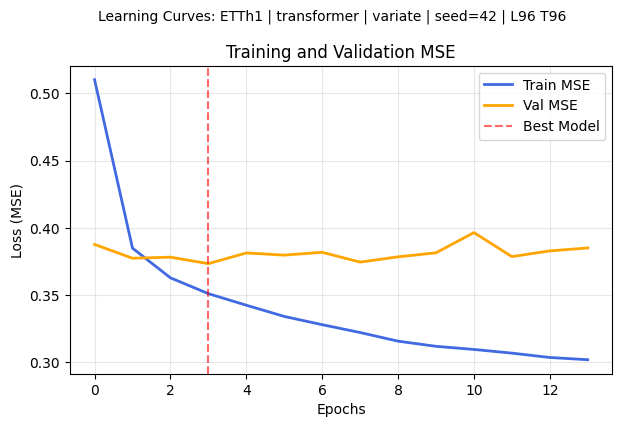

In [37]:
import numpy as np
import os
from utils.visualization import plot_learning_curves
from utils.plot_utils import make_suptitle


npz_metrics_path = os.path.join(save_artifacts_dir, "metrics.npz")
print("metrics.npz exists:", os.path.exists(npz_metrics_path))
print("metrics.npz path:", npz_metrics_path)

saved_data = np.load(npz_metrics_path)
history_loaded = {key: saved_data[key].tolist() for key in saved_data.files}

# 1. Prepare Title
suptitle = make_suptitle(configs)

# 2. Learning Curves
plot_learning_curves(
    history=history_loaded, 
    show=True, 
    save_path=None,
    suptitle=f"Learning Curves: {suptitle}"
)

## Evaluation

### Save npz loader preds
Load best model weights + evaluate test split + save NPZ (for plots)

In [27]:
import os
import torch

weights_path = os.path.join(save_artifacts_dir, "best_model.pt")
print("best_model exists:", os.path.exists(weights_path))
print("weights_path:", weights_path)

model_eval = TransformerModel(configs=configs, verbose=False).to(configs.device)
model_eval.load_state_dict(torch.load(weights_path, map_location=configs.device))
print("Loaded best weights from:", weights_path)


best_model exists: True
weights_path: runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/train/best_model.pt
Loaded best weights from: runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/train/best_model.pt


In [ ]:
from engine.evaluator import Evaluator


evaluator = Evaluator(device=configs.device)
# This will:
# 1. Evaluate Train, Val, and Test
# 2. Save ONLY 'post_training_metrics.json'
# 3. Save NPZs only for 'val' and 'test' (per your choice)


# all_results = evaluator.evaluate_splits(
#     model=model,
#     train_loader=train_loader,
#     val_loader=val_loader,
#     test_loader=test_loader,
#     save_dir="some_dummy_path",
#     # save_npz_splits=("val", "test"), 
#     save_npz_splits=None,
#     save_summary=False,
#     verbose=True,
# )

all_results = evaluator.evaluate_splits(
    model=model_eval,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    save_dir=save_test_dir,
    save_npz_splits=("val", "test"), 
    save_summary=True,
    verbose=True,
)




--- 🧪 Starting Split Evaluation (NPZ targets: ['val', 'test']) ---

[evaluator] Processing split: train...
[evaluator] Inference complete: X(18221, 96, 321), Y(18221, 96, 321), P(18221, 96, 321)

[evaluator] Processing split: val...
[evaluator] Inference complete: X(3755, 96, 321), Y(3755, 96, 321), P(3755, 96, 321)
[evaluator] Saved NPZ  -> runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/test/val_outputs.npz

[evaluator] Processing split: test...
[evaluator] Inference complete: X(3755, 96, 321), Y(3755, 96, 321), P(3755, 96, 321)
[evaluator] Saved NPZ  -> runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/test/test_outputs.npz
[evaluator] Saved Summary JSON -> runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/test/post_training_metrics.json


In [ ]:

# --- 🧪 Starting Split Evaluation (NPZ targets: ['val', 'test']) ---

# [evaluator] Processing split: train...
# [evaluator] Inference complete: X(12003, 96, 7), Y(12003, 96, 7), P(12003, 96, 7)

# [evaluator] Processing split: val...
# [evaluator] Inference complete: X(2422, 96, 7), Y(2422, 96, 7), P(2422, 96, 7)
# [evaluator] Saved NPZ  -> runs/ETTh1/variate/transformer/L96_T96/seed_42/2026-02-23_15-27/test/val_outputs.npz

# [evaluator] Processing split: test...
# [evaluator] Inference complete: X(2422, 96, 7), Y(2422, 96, 7), P(2422, 96, 7)
# [evaluator] Saved NPZ  -> runs/ETTh1/variate/transformer/L96_T96/seed_42/2026-02-23_15-27/test/test_outputs.npz
# [evaluator] Saved Summary JSON -> runs/ETTh1/variate/transformer/L96_T96/seed_42/2026-02-23_15-27/test/post_training_metrics.json

In [30]:
all_results

{'train': {'mse': 0.14135286211967468,
  'mae': 0.2429792433977127,
  'num_windows': 18221},
 'val': {'mse': 0.1380912810564041,
  'mae': 0.23719801008701324,
  'num_windows': 3755},
 'test': {'mse': 0.155020609498024,
  'mae': 0.2508084774017334,
  'num_windows': 3755}}

### Plot forecasts

In [ ]:
import os

# val_outputs.npz or test_outputs.npz for plots
npz_path = os.path.join(save_test_dir, "test_outputs.npz")

print(f"Targeting NPZ: {npz_path}")
print(f"File exists: {os.path.exists(npz_path)}")

Targeting NPZ: runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/test/test_outputs.npz
File exists: True


In [35]:
import importlib
import utils.visualization, utils.plot_utils
importlib.reload(utils.visualization)
importlib.reload(utils.plot_utils)
from utils.visualization import plot_forecasts_from_npz
from utils.plot_utils import make_suptitle


# 1. Title setup
filename = os.path.basename(npz_path)
split_name = filename.split("_")[0] if "_" in filename else "test"
suptitle = make_suptitle(configs, split_name=split_name)


# 2. Run plot
# We use the 'test_outputs.npz' path constructed earlier
png_path = plot_forecasts_from_npz(
    npz_path=npz_path,
    window_indices="random",
    num_random=7,
    seed=40,
    channel_idx=-1,
    save_dir=save_test_dir,
    show=False,
    verbose=True,
    suptitle=suptitle,
)



[plot] Loaded NPZ : X(3755, 96, 321), Y(3755, 96, 321), P(3755, 96, 321)
[plot] Available windows: N=3755 | lookback L=96 | horizon T=96 | channels V=321
[plot] Using random window_indices (k=7): [1642, 2737, 3535, 117, 2601, 80, 2105]
[plot] Saved -> runs/ECL/variate/transformer/L96_T96/seed_42/2026-02-25_23-31/test/test_7_forecasts_ch-1.png


In [ ]:
# [plot] Loaded NPZ : X(2422, 96, 7), Y(2422, 96, 7), P(2422, 96, 7)
# [plot] Available windows: N=2422 | lookback L=96 | horizon T=96 | channels V=7
# [plot] Using random window_indices (k=5): [1765, 51, 1678, 1357, 1059]
# [plot] Saved -> runs/ETTh1/variate/transformer/L96_T96/seed_42/2026-02-23_15-27/test/val_5_forecasts_ch-1_v3.png